## Machine Learning: Modelo Supervisado No 3. El Modelo KNN

### Andrés Eduardo Rangel Jiménez


- Economista `(Universidad del Valle, Colombia)`

- MSc en Econometria `(Universidad Torcuato Di Tella, Argentina)`

- PhD en Dirección de Empresas `(Universidad de Valencia, España)`

## Bases de datos utilizadas:

- `Social_Network_Ads.csv`
- `fetch_california_housing`

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import  RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc

# Saving the model
import pickle
## to ignore waarning
import warnings
warnings.filterwarnings("ignore")#, category=DeprecationWarning)

In [55]:
from IPython.display import HTML, display

with open("Knn_didactico.html", "r", encoding="utf-8") as f:
    html_content = f.read()

display(HTML(html_content))

## Modelo KNN. Una introducción 
```

kNN es un algoritmo de aprendizaje automático supervisado. En los modelos supervisados, hay dos tipos de variables al mismo tiempo:

Una variable de destino, que también se denomina variable dependiente o variable y.Variables independientes, que también se conocen como variables x o variables explicativas.

La variable objetivo es la variable que quieres predecir. Depende de las variables independientes y no es algo que sepas de antemano. Las variables independientes son variables que sí conoces de antemano. Puedes introducirlas en una ecuación para predecir la variable objetivo. De esta manera, es relativamente similar al caso y = ax + b.

El algoritmo kNN puede considerarse un sistema de votación, donde la etiqueta de clase mayoritaria determina la etiqueta de clase de un nuevo punto de datos entre sus vecinos 'k' (donde k es un entero) más cercanos en el espacio de características. Imagine un pequeño pueblo con unos pocos cientos de residentes y debe decidir por qué partido político debe votar. Para ello, puede ir a sus vecinos más cercanos y preguntarles a qué partido político apoyan. Si la mayoría de sus 'k' vecinos más cercanos apoyan al partido A, lo más probable es que usted también vote por el partido A. Esto es similar a cómo funciona el algoritmo kNN, donde la etiqueta de clase mayoritaria determina la etiqueta de clase de un nuevo punto de datos entre sus k vecinos más cercanos.

Cuando llega un nuevo punto de datos, el algoritmo kNN, como indica su nombre, comenzará por encontrar los vecinos más cercanos de este nuevo punto de datos. Luego toma los valores de esos vecinos y los usa como una predicción para el nuevo punto de datos.

Como ejemplo intuitivo de por qué esto funciona, piensa en tus vecinos. Tus vecinos suelen ser relativamente similares a ti. Probablemente estén en la misma clase socioeconómica que tú. Tal vez tengan el mismo tipo de trabajo que tú, tal vez sus hijos vayan a la misma escuela que los tuyos, etc. Pero para algunas tareas, este tipo de enfoque no es tan útil. Por ejemplo, no tendría sentido mirar el color favorito de su vecino para predecir el suyo.

El algoritmo kNN se basa en la noción de que se pueden predecir las características de un punto de datos en función de las características de sus vecinos. En algunos casos, este método de predicción puede ser exitoso, mientras que en otros casos puede que no. 

## Simulacion de datos para la explicación de un modelo KNN
```
Tenemos dos características de entrada (x e y) y luego una clase de destino (clase). Las características de entrada que están etiquetadas previamente con nuestra clase de destino se utilizarán para predecir la clase de los nuevos datos. Tener en cuenta que, si bien aquí solo usamos dos características de entrada, este método funcionará con cualquier cantidad de variables:

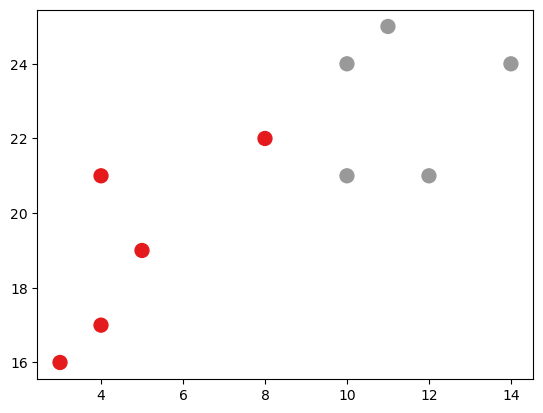

In [8]:
import matplotlib.pyplot as plt

x = [4, 5, 10, 4, 3, 11, 14 , 8, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]
classes = [0, 0, 1, 0, 0, 1, 1, 0, 1, 1]

plt.scatter(x, y, c=classes, cmap=plt.cm.Set1, s=100)  # Set1 = colores fuertes
plt.show()


El anterior codigo convierte las características de entrada en un conjunto de puntos:

In [4]:
data = list(zip(x, y))
print(data)

[(4, 21), (5, 19), (10, 24), (4, 17), (3, 16), (11, 25), (14, 24), (8, 22), (10, 21), (12, 21)]


Utilizando las características de entrada y la clase de destino, ajustamos un modelo KNN al modelo utilizando 1 vecino más cercano:

In [10]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(data, classes)

,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


```
Luego, podemos usar el mismo objeto KNN para predecir la clase de puntos de datos nuevos e imprevistos. Primero, creamos nuevas características x e y, y luego llamamos a knn.predict() en el nuevo punto de datos para obtener una clase de 0 o 1. Cuando graficamos todos los datos junto con el nuevo punto y la clase, podemos ver que se lo ha etiquetado en azul con la clase 1. La anotación de texto es solo para resaltar la ubicación del nuevo punto:

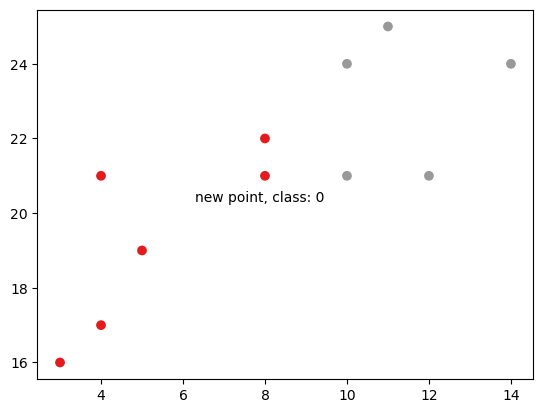

In [12]:
new_x = 8
new_y = 21
new_point = [(new_x, new_y)]

prediction = knn.predict(new_point)

plt.scatter(x + [new_x], y + [new_y],cmap=plt.cm.Set1, c=classes + [prediction[0]])
plt.text(x=new_x-1.7, y=new_y-0.7, s=f"new point, class: {prediction[0]}")
plt.show()

In [16]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(data, classes)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


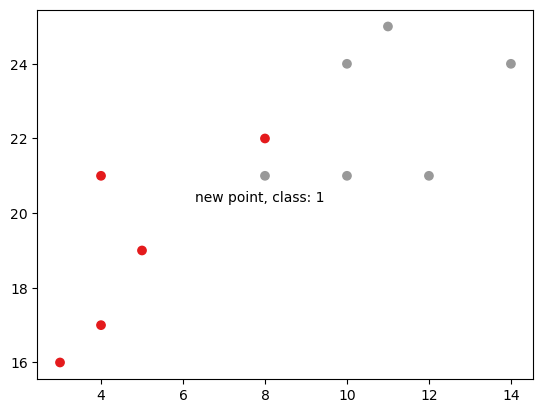

In [18]:
new_x = 8
new_y = 21
new_point = [(new_x, new_y)]

prediction = knn.predict(new_point)

plt.scatter(x + [new_x], y + [new_y],cmap=plt.cm.Set1 , c=classes + [prediction[0]])
plt.text(x=new_x-1.7, y=new_y-0.7, s=f"new point, class: {prediction[0]}")
plt.show()

```
Sin embargo, cuando cambiamos el número de vecinos a 5, cambia el número de puntos utilizados para clasificar nuestro nuevo punto. Como resultado, también cambia la clasificación del nuevo punto: Cuando graficamos la clase del nuevo punto junto con los puntos más antiguos, observamos que el color ha cambiado según la etiqueta de clase asociada:

Se observa como estos modelos de clasificación dependen del ajuste el parametro k, llamado hiperparametro k.  En este caso hay que ajustar
este hiperparametro para luego mediante unas metricas que veremos mas adelante, analizar cual k ofrece el mejo desempeño del modelo.

NOTA: con metric como argumento puedo cambiar las distancias.

## Ejercicio  1. Utilizando KNN para clasificacion
```

Inspeccionemos inicialmente la base con la que vamos a trabajar.Estaremos trabajando con una base de clientes sobre los cuales tenemos información demográfica y si compraron o no el producto que nosotros vendemos. Esta base tiene 5 variables (Identificador, Género, Edad, Salario Estimado, Y una variable categórica de si compró un producto o no)

In [400]:
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

ModuleNotFoundError: No module named 'google.colab'

In [7]:
## Importación de la base
datos=pd.read_csv("Social_Network_Ads.csv")
datos.head(10)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
5,15728773,Male,27,58000,0
6,15598044,Female,27,84000,0
7,15694829,Female,32,150000,1
8,15600575,Male,25,33000,0
9,15727311,Female,35,65000,0


In [9]:
datos.shape

(400, 5)

In [11]:
##Inspección simple
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [13]:
###Separemos la base entre covariables y etiqueta
x = datos.iloc[:,2:4]
y = datos.iloc[:,-1]

In [15]:
x.head()

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [17]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

In [19]:
datos['Purchased'].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

No hay desbalanceo

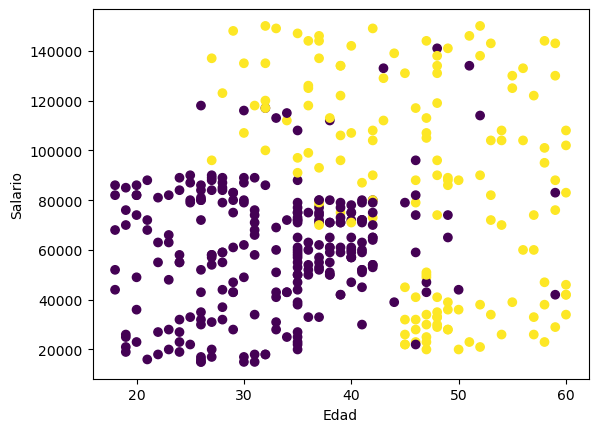

In [22]:
### Veamos cómo se separan los datos visualmente, con base en la etiqueta
plt.scatter(x['Age'],x['EstimatedSalary'],c=y)
plt.xlabel("Edad")
plt.ylabel("Salario")
plt.show()

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

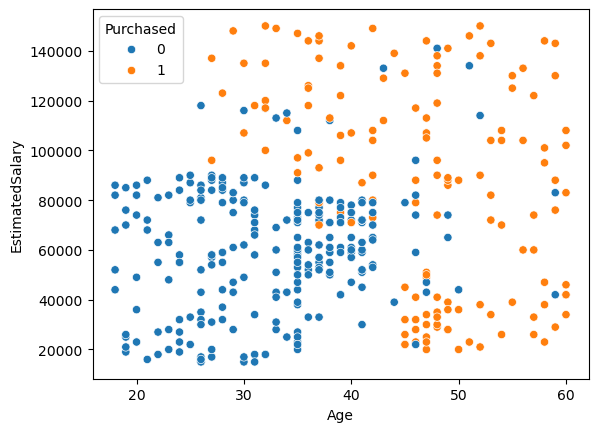

In [24]:
sns.scatterplot(x=datos['Age'],y=datos['EstimatedSalary'], hue=datos['Purchased'])

**División de datos en conjuntos de prueba y de entrenamiento**


```
A continuación, los datos se dividen en conjuntos de entrenamiento y prueba utilizando la función train_test_split del módulo sklearn.model_selection. El parámetro test_size especifica la proporción de los datos que se deben asignar al conjunto de prueba (en este caso, 20%) y se coloca un random state para permitir la reproducibildad del codigo.

In [28]:
# Split the data into training and test sets
SEED = 42
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state=SEED)

Veamos las estadisticas descriptivas:


In [31]:
datos.describe().T

,count,mean,std,min,25%,50%,75%,max
User ID,400.0,1.569154e+07,71658.321581,15566689.0,15626763.75,15694341.5,15750363.0,15815236.0
Age,400.0,3.765500e+01,10.482877,18.0,29.75,37.0,46.0,60.0
EstimatedSalary,400.0,6.974250e+04,34096.960282,15000.0,43000.00,70000.0,88000.0,150000.0
Purchased,400.0,3.575000e-01,0.479864,0.0,0.00,0.0,1.0,1.0


In [33]:
# Scale the features using StandardScaler
scaler = StandardScaler()
#Ajustar el escalador (scaler) SOLO con el conjunto de entrenamiento
X_train = scaler.fit_transform(X_train)
#Transformar también el conjunto de prueba (usando la media y std de entrenamiento)
X_test = scaler.transform(X_test)

In [35]:
print(X_train.shape)


(320, 2)


In [37]:
print(y_train.shape)

(320,)


In [39]:
print(X_test.shape)

(80, 2)


In [41]:
print(y_test.shape)

(80,)


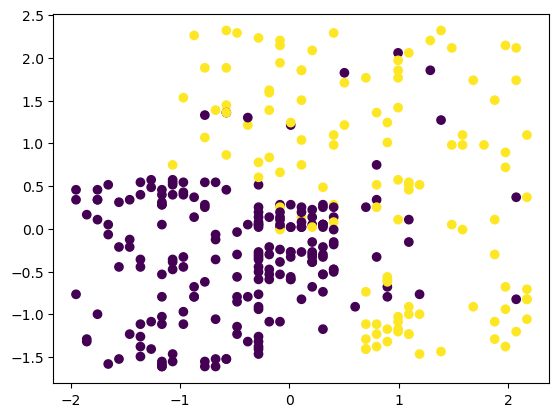

In [43]:
##Veamos la nueva gráfica en los datos para entrenar
plt.scatter(X_train[:,0],X_train[:,1],c=y_train)

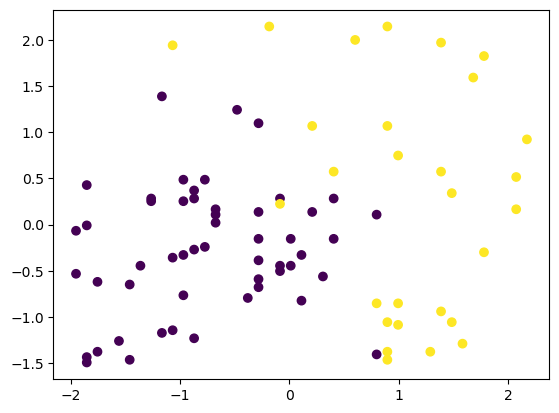

In [45]:
##La misma gráfica en los datos test
plt.scatter(X_test[:,0],X_test[:,1],c=y_test)

In [47]:
###Ahora sí, manos a la obra... ¡Encontremos nuestra primera predicción!
knn= KNeighborsClassifier(n_neighbors=5)

##Entrenamos nuestro modelo
knn.fit(X_train,y_train)

##Evaluamos 
y_pred=knn.predict(X_test)

error=(y_pred!=y_test).mean()*100

print(f"Predijimos un {error}% de datos en test incorrectamente")


Predijimos un 8.75% de datos en test incorrectamente


```
Recordemos que en el modelo logit nuestro error de predicción nos dio 13.75%.  Hemos disminuido el error con el modelo KNN, diciendonnos que KNN es mejor que el modelo logit para realizar clasificaciónes para este problema en especifico. No obstante podemos mejorar el desempeño del modelo KNN mediante la tecnica de Fine Tuning

##  Fine Tuning en el algoritmo de KNN

In [51]:
## Escogencia del hiperparámetro K
vecinos = list(range(2, 20, 1))
#significa lo siguiente en Python:
#range(2, 100, 2) crea una secuencia de números que:
#empieza en 2 (el primer argumento),
#llega hasta 20 pero sin incluirlo (el segundo argumento),
#va avanzando de 1 en 1 (el tercer argumento, el paso o step).
#list(...) convierte esa secuencia en una lista de Python.
#Por lo tanto, vecinos será una lista con todos los números pares del 2 al 20:

errores_insample = []
errores_outsample = []
for k in vecinos:
    neigh = KNeighborsClassifier(n_neighbors = k)
    neigh.fit(X_train, y_train)
    y_hat_insample = neigh.predict(X_train)
    y_hat_outsample = neigh.predict(X_test)

    error_insample = (y_hat_insample != y_train).mean()
    errores_insample.append(error_insample)
    error_outsample = (y_hat_outsample != y_test).mean()
    errores_outsample.append(error_outsample)

resultados = pd.DataFrame({"K": vecinos, "Error de entrenamiento": errores_insample, "Error de prueba": errores_outsample})

# --- Encontrar el mejor K (menor error de prueba) ---
min_error = min(errores_outsample)
best_k = resultados.loc[resultados["Error de prueba"].idxmin(), "K"]

print(f"El menor error de prueba es {min_error:.4f} con n_neighbors = {best_k}")


El menor error de prueba es 0.0625 con n_neighbors = 7


In [53]:
## Escogencia del hiperparámetro K
vecinos = list(range(2, 100, 2))
#significa lo siguiente en Python:
#range(2, 100, 2) crea una secuencia de números que:
#empieza en 2 (el primer argumento),
#llega hasta 100 pero sin incluirlo (el segundo argumento),
#va avanzando de 2 en 2 (el tercer argumento, el paso o step).
#list(...) convierte esa secuencia en una lista de Python.
#Por lo tanto, vecinos será una lista con todos los números pares del 2 al 98:

errores_insample = []
errores_outsample = []
for k in vecinos:
    neigh = KNeighborsClassifier(n_neighbors = k)
    neigh.fit(X_train, y_train)
    y_hat_insample = neigh.predict(X_train)
    y_hat_outsample = neigh.predict(X_test)

    error_insample = (y_hat_insample != y_train).mean()
    errores_insample.append(error_insample)
    error_outsample = (y_hat_outsample != y_test).mean()
    errores_outsample.append(error_outsample)

resultados = pd.DataFrame({"K": vecinos, "Error de entrenamiento": errores_insample, "Error de prueba": errores_outsample})

# --- Encontrar el mejor K (menor error de prueba) ---
min_error = min(errores_outsample)
best_k = resultados.loc[resultados["Error de prueba"].idxmin(), "K"]

print(f"El menor error de prueba es {min_error:.4f} con n_neighbors = {best_k}")

El menor error de prueba es 0.0625 con n_neighbors = 20


```
Esto es una limitación fundamental del Fine Tuning manual. Solo puedes encontrar el mejor k dentro del rango que exploraste. Si el óptimo real está fuera de ese rango, simplemente no lo vas a ver.
La primera búsqueda exploró k del 2 al 19 (solo impares y pares), y dentro de ese universo restringido el mejor fue k=7.
La segunda búsqueda exploró hasta k=98 pero solo valores pares, por lo que k=7 ni siquiera estaba disponible como candidato. Dentro de su universo, el mejor fue k=20.

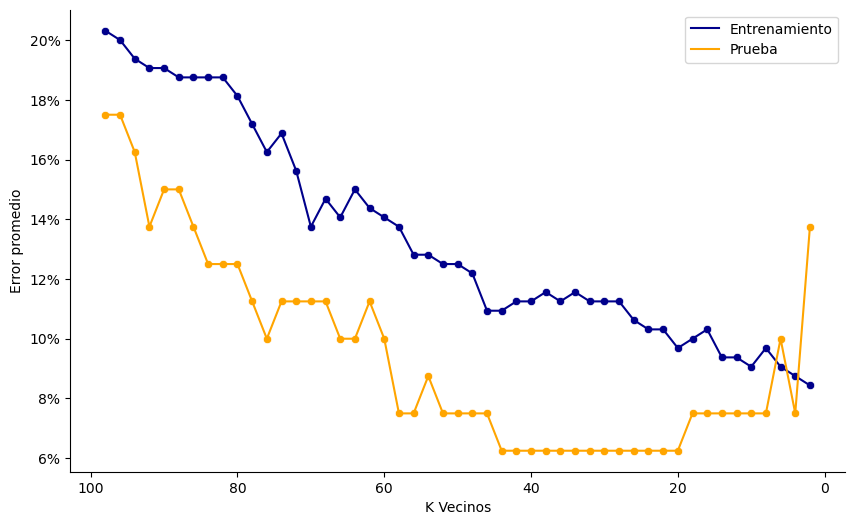

In [56]:
fig, ax = plt.subplots(figsize = (10, 6), dpi = 100)
sns.despine()

sns.lineplot(data = resultados, x = "K", y = "Error de entrenamiento", ax = ax, color = "darkblue")
sns.scatterplot(data = resultados, x = "K", y = "Error de entrenamiento", ax = ax, color = "darkblue")
sns.lineplot(data = resultados, x = "K", y = "Error de prueba", ax = ax, color = "orange")
sns.scatterplot(data = resultados, x = "K", y = "Error de prueba", ax = ax, color = "orange")
ax.legend(handles = ax.lines, labels = ["Entrenamiento", "Prueba", "Error irreducible"])

ax.set_xlabel("K Vecinos")
ax.set_ylabel("Error promedio")
ax.invert_xaxis()
ax.yaxis.set_major_formatter("{x:.0%}")

```
Si bien alcanzamos el menor error de pronostico (6.25%) con k=7 también lo alcanzamos con k=10, no obstante elegimos 7 pues es mas eficiente para el algoritmo probar con 7 vecinos que con 10.

```
De hecho apliquemos de nuevo el algoritmo KNN para clasificar y evaluemos su desempeño con K=7 :

In [60]:
knn= KNeighborsClassifier(n_neighbors=20)

##Entrenamos nuestro modelo
knn.fit(X_train,y_train)

##Evaluamos 
y_pred=knn.predict(X_test)

error=(y_pred!=y_test).mean()*100

print(f"Predijimos un {error}% de datos en test incorrectamente")

Predijimos un 6.25% de datos en test incorrectamente


In [62]:
##Habrá overfitting?
knn_prueba= KNeighborsClassifier(n_neighbors=7)
##Entrenamos nuestro modelo
knn_prueba.fit(X_train,y_train)

y_pred=knn_prueba.predict(X_test)
y_pred_train=knn_prueba.predict(X_train) ##hacemos el predict en train set

acc_test=metrics.accuracy_score(y_test,y_pred)
acc_train=metrics.accuracy_score(y_train,y_pred_train)

print("Accuracy en test: {:.2f}".format(acc_test) )
print("Accuracy ent train: {:.2f}".format(acc_train))

Accuracy en test: 0.94
Accuracy ent train: 0.92


```
No hay overfitting, hay algo más interesante, el patrón clásico de overfitting es el opuesto: accuracy en train muy alto y en test más bajo, porque el modelo "memoriza" los datos de entrenamiento y falla al generalizar.
Aquí ocurre lo contrario: el modelo rinde mejor en test que en train, lo cual es inusual pero no necesariamente problemático. Hay varias explicaciones posibles.
La más probable es la composición de los sets. Si el test set tiene una distribución de clases más "fácil" de clasificar que el train set, 

## Métricas de evaluación
```
Una matriz de confusión te permite evaluar el rendimiento de un modelo de clasificación, mostrando cuántas predicciones acertó y en qué se equivocó, comparando los valores predichos con los reales. Sirve para saber cuánto acertamos o nos equivocamos en cada clase. Los valores que eran correctos y fueron correctamente predichos se llaman verdaderos positivos. Los que fueron predichos como positivos pero no lo eran, se llaman falsos positivos. Se utiliza la misma nomenclatura de verdaderos negativos y falsos negativos para los valores negativos.

¿Cómo se construye una matriz de confusión en Python?
Supongamos que ya tienes un modelo entrenado y dos vectores:

- y_true (actual label): etiquetas reales
  
- y_pred (predicted label): etiquetas predichas por el modelo


In [66]:
##Un primer paso para identificar cuál métrica deberíamos usar, es ver el balanceo de las categorías en la muestra:
datos['Purchased'].value_counts(normalize=True)

Purchased
0    0.6425
1    0.3575
Name: proportion, dtype: float64

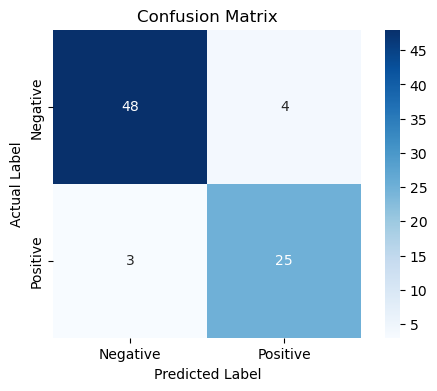

[[48  4]
 [ 3 25]]


In [68]:
knn= KNeighborsClassifier(n_neighbors=5)

##Entrenamos nuestro modelo
knn.fit(X_train,y_train)

##Matriz de confusión
y_pred=knn.predict(X_test)

cm=metrics.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", square=True,
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()
print(cm)

                 Predicho
                 |  0     |  1
         ________|________|________         
    real       0 | TN     | FP
       __________|________|__________
               1 | FN     | TP 

```
- Se predijeron correctamente 48 negativos (no compra) y 26 positivos (si compra)
- Se cometieron 4 falsos positivos (predijo positivo (compra) pero era negativo (no compra).
- Se cometieron 2 falsos negativos (predijo negativos (no compra)  pero eran positivos (compra)

## Evaluación de KNN para clasificación

Para evaluar el clasificador KNN, también podemos utilizar el método de puntuación, pero ejecuta una métrica diferente, ya que estamos puntuando un clasificador y no un regresor. 

##### Precision:

La métrica básica para la clasificación es la precisión: describe cuántas predicciones acertó nuestro clasificador. El valor de precisión más bajo es 0 y el más alto es 1. Por lo general, multiplicamos ese valor por 100 para obtener un porcentaje.

$$
Accuracy=\frac{number\:\ of\:\ correct\:\  predictions}{total\:\ number\:\ of\:\ predictionsn}
$$

##### Recall: 

Para saber cuántos de los verdaderos positivos fueron identificados por nuestro clasificador. El recall se calcula dividiendo los verdaderos positivos por todo lo que debería haberse predicho como positivo.

$$
Recall = \frac{\text{true positive}}{\text{true positive} + \text{false negative}}
$$

##### F1 Score

Puntuación F1: es la media equilibrada o armónica de precisión y recuperación. El valor más bajo es 0 y el más alto es 1. Cuando la puntuación F1 es igual a 1, significa que se predijeron correctamente todas las clases;

$$
\text{f1-score} = 2* \frac{\text{precision} * \text{recall}}{\text{precision} + \text{recall}}
$$



In [73]:
##Accuracy
acc=metrics.accuracy_score(y_test,y_pred)
print("El accuracy score es " + str(acc))


##Recall
rec=metrics.recall_score(y_test,y_pred)
print("El recall score es " + str(rec))

##f1-score
f1=metrics.f1_score(y_test,y_pred)
print("El F1 score es " + str(f1))

El accuracy score es 0.9125
El recall score es 0.8928571428571429
El F1 score es 0.8771929824561403


##### NOTA: 

Recordemos que en el modelo Logit, la precision nos dio 86,25%. Hemos mejorado la clasificacion con el modelo KNN

In [325]:
classifier5 = KNeighborsClassifier(n_neighbors=5)
classifier5.fit(X_train, y_train)
y_pred5 = classifier5.predict(X_test)
print(classification_report(y_test, y_pred5))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93        52
           1       0.86      0.89      0.88        28

    accuracy                           0.91        80
   macro avg       0.90      0.91      0.90        80
weighted avg       0.91      0.91      0.91        80



## Cross Validation
```
La validación cruzada (cross-validation) es en realidad el método más robusto para hacer fine tuning, y tiene varias ventajas sobre el enfoque manual de train_test_split.

- El problema con el enfoque manual (train/test split)

Con un único split 80/20, el "mejor K" que encontraste depende de cuáles 80 observaciones cayeron en train y cuáles 20 en test. Si hubieras hecho un split diferente, probablemente habrías encontrado un K óptimo distinto. El resultado es ruidoso porque evaluás con una sola muestra de test.

- Cross-Validation K-Fold: la idea

En lugar de dividir los datos una sola vez, el dataset se divide en k partes iguales (folds). El modelo se entrena k veces: cada vez usa k-1 folds para entrenar y 1 fold diferente para validar. Al final, el error reportado es el promedio de los k errores — mucho más estable.
Con 5-fold CV en tus datos (400 observaciones), cada fold tiene 80 observaciones, y cada K se evalúa en la totalidad del dataset rotando el conjunto de validación.

- Comparación de ambos enfoques

| Aspecto                        | Train/Test manual      | Cross-Validation (5-fold)    |
|--------------------------------|------------------------|------------------------------|
| Evaluaciones por K             | 1                      | 5                            |
| Estabilidad del resultado      | Depende del split      | Mucho más estable            |
| Uso de datos                   | 80% train, 20% test    | 100% para validar en rotación|
| Costo computacional            | Bajo                   | ~5x más lento                |
| Riesgo de "suerte" en el split | Alto                   | Muy bajo                     |


¿Cuándo usar cada uno?

El enfoque manual usado está bien para un primer análisis rápido y cuando el dataset es grande. Cross-validation con 5 o 10 folds es la práctica estándar cuando el dataset es moderado (como tus 400 observaciones) porque usa todos los datos para validación y da un resultado más confiable.

Un flujo típico en la práctica sería: usar cross-validation para encontrar el K óptimo sobre los datos de train, y luego evaluar una sola vez sobre el test set al final para reportar el desempeño final — el test set nunca se toca durante la búsqueda del K.

In [58]:
# Datos ya estandarizados (X_train, y_train del split original)
k_values = range(2, 20, 1)
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    # cv=5 → 5-fold cross validation, scoring='accuracy'
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())  # promedio de los 5 folds

# Encontrar el K óptimo
best_k = list(k_values)[np.argmax(cv_scores)]
best_acc = max(cv_scores)
print(f"K óptimo: {best_k}, Accuracy CV promedio: {best_acc:.4f}")

K óptimo: 9, Accuracy CV promedio: 0.9062


## Analisis de resultados

```
Train/Test manual → K óptimo = 7, Accuracy = 93.75%
Cross-Validation 5-fold → K óptimo = 9, Accuracy = 90.62%

Dos métodos, dos respuestas distintas. ¿Cuál creerle?

La respuesta corta: al cross-validation. El 93.75% del método manual probablemente está inflado — ese split 80/20 particular "le cayó bien" al K=7 por casualidad. El 90.62% de CV es un estimado más honesto porque promedia 5 evaluaciones diferentes, cada una con un conjunto de validación distinto.

La diferencia entre 93.75% y 90.62% no es que el modelo empeoró — es que el CV está midiendo mejor. Si entrenaras con K=7 y evaluaras sobre datos completamente nuevos del mundo real, probablemente verías algo más cercano al 90% que al 94%.

¿Y qué hacer con K=9?

El flujo correcto sería: ahora que CV te dijo que K=9 es el mejor, entrenas el modelo final con K=9 usando todos los datos de train, y lo evalúas una sola vez sobre el test set que guardaste desde el principio. Ese número final es el que reportas.

In [60]:
from sklearn import metrics

# Paso final: entrenar con el K óptimo encontrado por CV
knn_final = KNeighborsClassifier(n_neighbors=9)
knn_final.fit(X_train, y_train)

# Evaluar UNA SOLA VEZ sobre test
y_pred_final = knn_final.predict(X_test)
error_final = (y_pred_final != y_test).mean() * 100
print(f"Error final con K=9: {error_final:.2f}%")

# Accuracy
acc = metrics.accuracy_score(y_test, y_pred_final)
print("El accuracy score es " + str(acc))

Error final con K=9: 6.25%
El accuracy score es 0.9375


Error final con K=9: 6.25%

Accuracy : 0.9375
Recall   : 0.9643
F1 Score : 0.9153
AUC-ROC  : 0.9708

Classification report:
              precision    recall  f1-score   support

           0     0.9796    0.9231    0.9505        52
           1     0.8710    0.9643    0.9153        28

    accuracy                         0.9375        80
   macro avg     0.9253    0.9437    0.9329        80
weighted avg     0.9416    0.9375    0.9382        80

Matriz de confusión:
[[48  4]
 [ 1 27]]


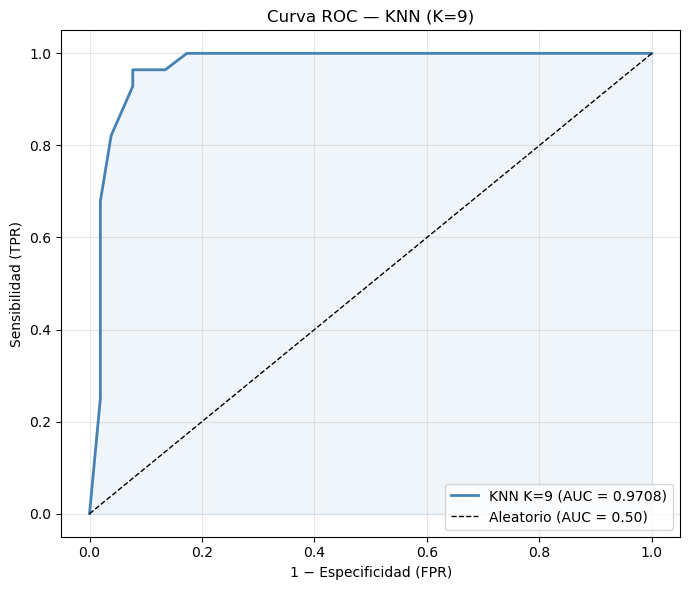

In [75]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
)
import matplotlib.pyplot as plt

# Paso final: entrenar con el K óptimo encontrado por CV
knn_final = KNeighborsClassifier(n_neighbors=9)
knn_final.fit(X_train, y_train)

# Evaluar UNA SOLA VEZ sobre test
y_pred_final = knn_final.predict(X_test)
y_prob_final = knn_final.predict_proba(X_test)[:, 1]   # prob. de la clase 1

error_final = (y_pred_final != y_test).mean() * 100
print(f"Error final con K=9: {error_final:.2f}%\n")

# ---- MÉTRICAS ----
acc      = accuracy_score(y_test, y_pred_final)
rec      = recall_score(y_test, y_pred_final)        # añade average='macro' si es multiclase
f1       = f1_score(y_test, y_pred_final)            # idem
auc_roc  = roc_auc_score(y_test, y_prob_final)

print(f"Accuracy : {acc:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"AUC-ROC  : {auc_roc:.4f}")

# ---- Reporte completo y matriz de confusión (opcional pero útil) ----
print("\nClassification report:")
print(classification_report(y_test, y_pred_final, digits=4))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_final))

# ---- Curva ROC ----
fpr, tpr, _ = roc_curve(y_test, y_prob_final)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'KNN K=9 (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatorio (AUC = 0.50)')
plt.fill_between(fpr, tpr, alpha=0.08, color='steelblue')
plt.xlabel('1 − Especificidad (FPR)')
plt.ylabel('Sensibilidad (TPR)')
plt.title('Curva ROC — KNN (K=9)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Ejercicio 2. Utilizando KNN para fines de regresion 
```
Los algoritmos de aprendizaje automático supervisado se pueden dividir en dos grupos según el tipo de variable objetivo que pueden predecir:

La clasificación es una tarea de predicción con una variable objetivo categórica. La regresión es una tarea de predicción en la que la variable objetivo es numérica.

Vamos a utilizar el conjunto de datos de vivienda de California para ilustrar cómo funciona el algoritmo KNN. El conjunto de datos se derivó del censo de los EE. UU. de 1990. Una fila del conjunto de datos representa el censo de un grupo de bloques.Un grupo de bloques es la unidad geográfica más pequeña para la que la Oficina del Censo de los EE. UU. publica datos de muestra. Además de grupo de bloques, otro término utilizado es hogar, un hogar es un grupo de personas que residen en una casa.

El conjunto de datos ya es parte de la biblioteca Scikit-Learn, solo necesitamos importarlo y cargarlo como un marco de datos:

In [62]:
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing()
print(california.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [493]:
print(california.data.shape)
print(california.target.shape)

(20640, 8)
(20640,)


In [495]:
#load the feature names
california.feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

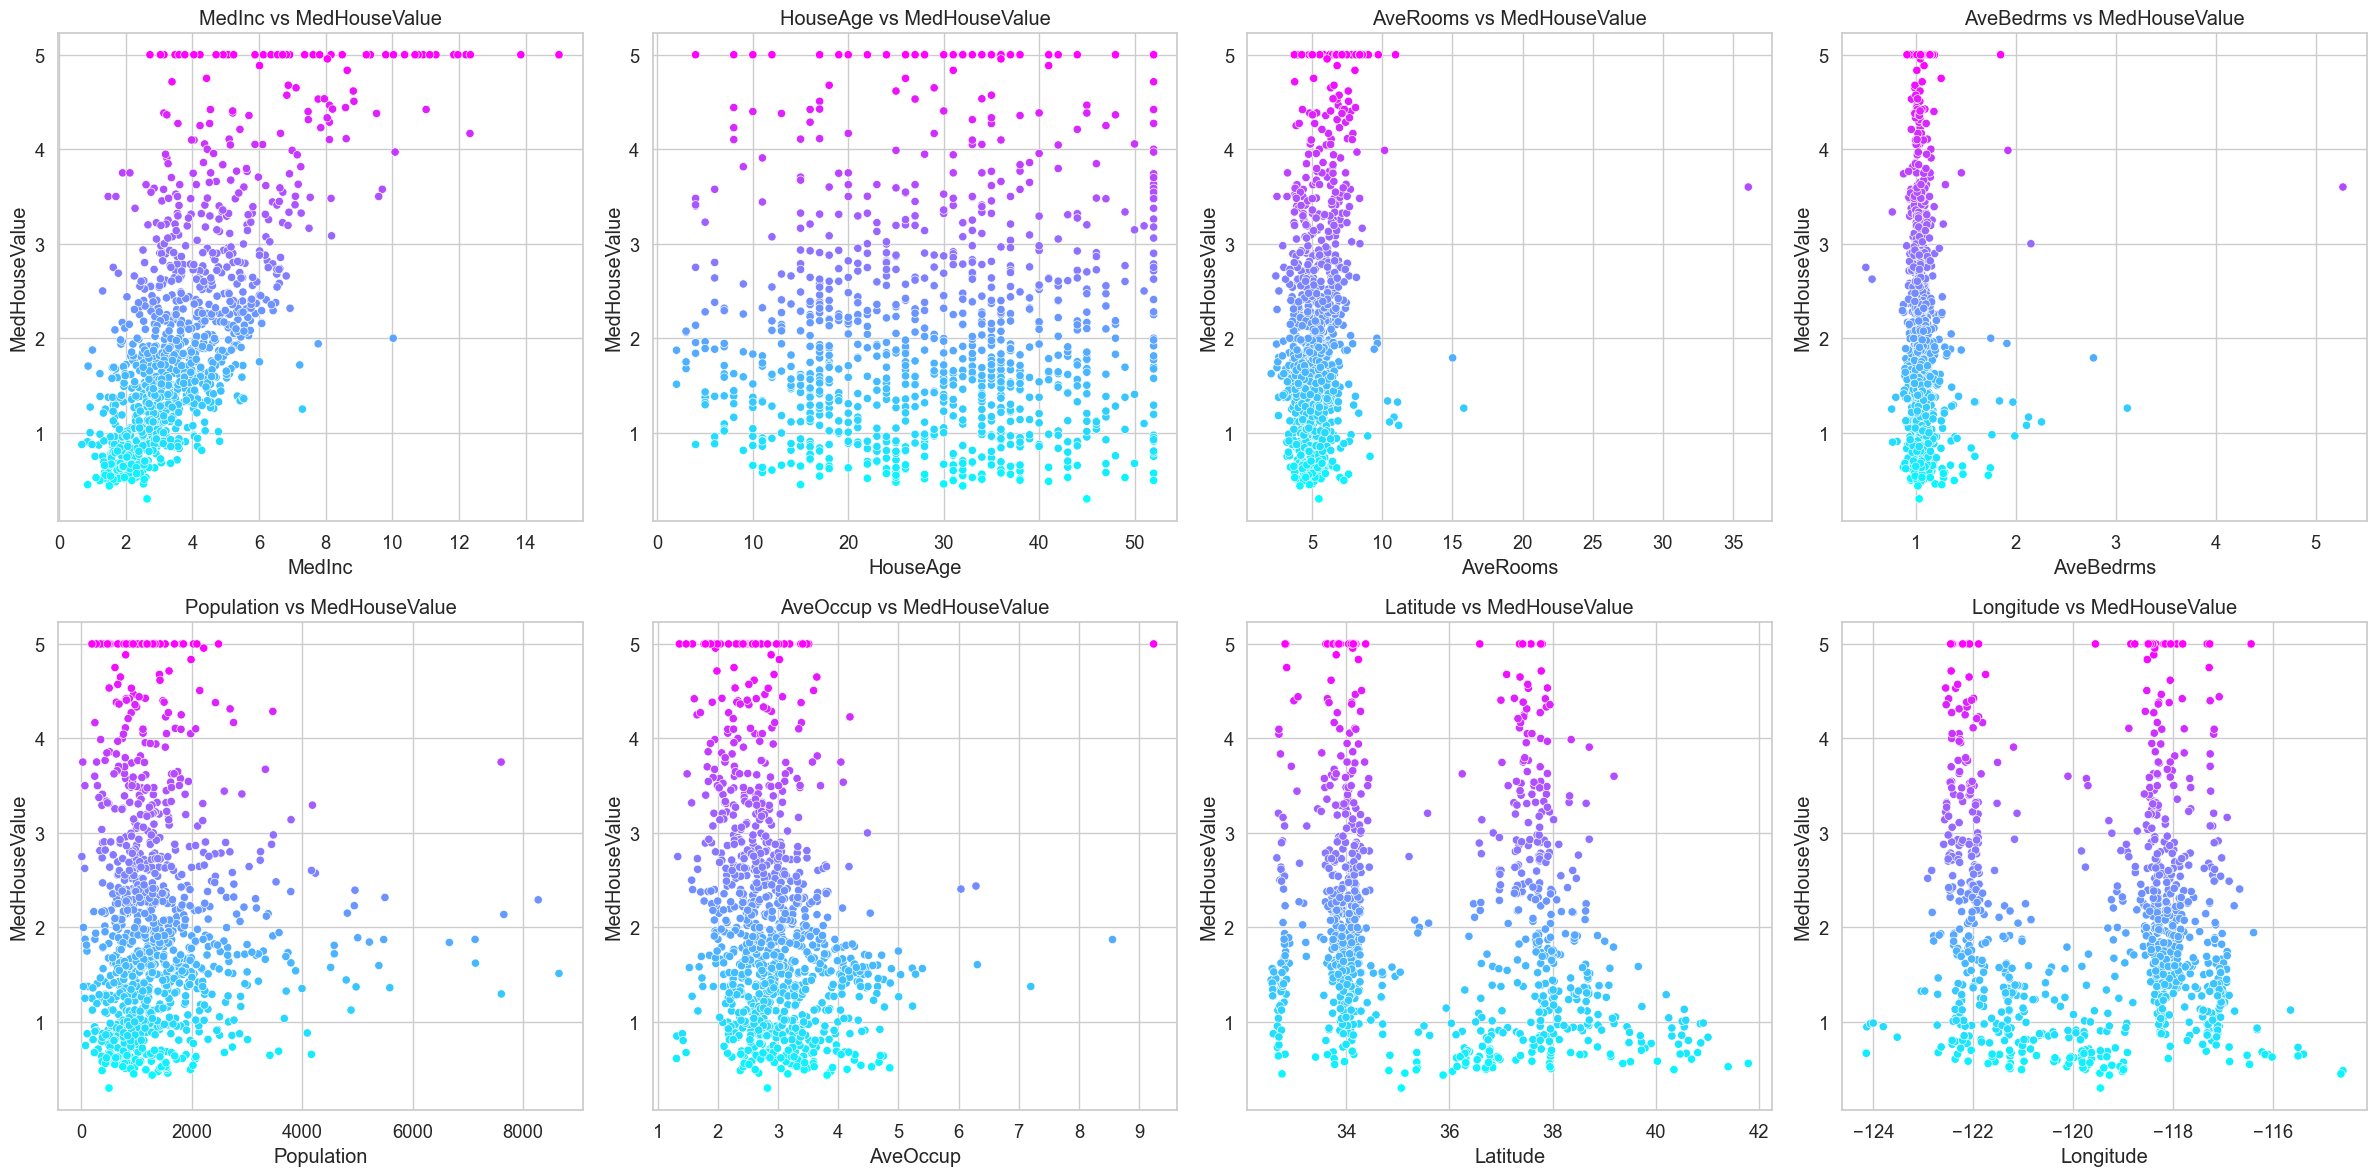

In [64]:
# Cargar dataset
california = fetch_california_housing()
df = pd.DataFrame(california.data, columns=california.feature_names)
df["MedHouseValue"] = california.target

# Crear muestra automática (máximo 1000 filas)
sample_df = df.sample(n=min(1000, len(df)), random_state=42)

# Configuración de estilo
sns.set(font_scale=1.2)
sns.set_style('whitegrid')

# Crear cuadrícula de subplots
fig, axes = plt.subplots(2, 4, figsize=(24, 12))
axes = axes.flatten()

# Graficar cada feature contra el precio medio
for i, feature in enumerate(california.feature_names):
    sns.scatterplot(
        data=sample_df,
        x=feature,
        y="MedHouseValue",
        hue="MedHouseValue",
        palette="cool",
        legend=False,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs MedHouseValue")

plt.tight_layout()
plt.show()

Un analisis grafico para aproximarnos a un analisis exploratorios nos dice que existe una relación directa ente el precio de la vivienda y el ingreso medio 
de la familia. Con las demas variables no se identifica el tipo de relación entre la variable precio de la vivienda y el resto de variables explicativas.


Estamos utilizando un algoritmo basado en la distancia, y los algoritmos basados ​​en la distancia sufren mucho cuando los datos no están en la misma escala, como estos datos. La escala de los puntos puede distorsionar (y en la práctica, casi siempre lo hace) la distancia real entre los valores. Por esto es necesrario estandarizar.

##### Dividiendo la muestra en entrenamiento y control

In [66]:
from sklearn.model_selection import train_test_split
SEED = 11  

X_train, X_test, y_train, y_test = train_test_split(california.data,
                                                    california.target, test_size=0.25, random_state=SEED)
print(X_train.shape)
print(X_test.shape)

(15480, 8)
(5160, 8)


##### Escalado de características para la regresión KNN

Al importar StandardScaler transformamos  los conjuntos de datos de entrenamiento y de prueba, realizando el escalado de características. De hecho observando 
la desviación estandar (raiz cuadarada de la varianza), vemos std muy disimiles. Cuando esto sucede es imperatorio estandrizar las variables. 

In [68]:
col_names=['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
df = pd.DataFrame(X_train, columns=col_names)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,15480.0,3.855703,1.901186,0.499900,2.548750,3.522050,4.729850,15.000100
HouseAge,15480.0,28.697416,12.607306,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,15480.0,5.420580,2.417548,0.846154,4.424901,5.206629,6.041856,132.533333
AveBedrms,15480.0,1.097474,0.473450,0.333333,1.006263,1.048676,1.098765,34.066667
Population,15480.0,1429.603424,1158.313459,3.000000,785.000000,1165.500000,1722.000000,35682.000000
AveOccup,15480.0,3.094465,11.821299,0.692308,2.427658,2.819961,3.288067,1243.333333
Latitude,15480.0,35.628122,2.131421,32.540000,33.930000,34.250000,37.712500,41.950000
Longitude,15480.0,-119.568130,2.004308,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Fit only on X_train
scaler.fit(X_train)

# Scale both X_train and X_test
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

##### Entrenamiento y predicción de regresión KNN

In [74]:
from sklearn.neighbors import KNeighborsRegressor
regressor = KNeighborsRegressor(n_neighbors=7)
regressor.fit(X_train, y_train)

,n_neighbors,7
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


En el código anterior, n_neighbors es el valor de K, o la cantidad de vecinos que el algoritmo tendrá en cuenta para elegir un nuevo valor de vivienda promedio. 5 es el valor predeterminado para KNeighborsRegressor(). No existe un valor ideal para K y se selecciona después de realizar pruebas y evaluaciones; sin embargo, para comenzar, 5 es un valor que se usa comúnmente para KNN y, por lo tanto, se estableció como el valor predeterminado. Como podemos ver este modelo no es explicativo, no hay una salida con resultados como si lo obteniamos del modelo de regresión en el cual nos arrojaba las estimaciones (y con ello el poder infererir el tipo de relación entre las X y Y, ni tampoco nos arroja signicancia individual ni en conjunto entre otras metricas)

El paso final es hacer predicciones sobre nuestros datos de prueba. Para ello, ejecute el siguiente script:

In [76]:
y_pred = regressor.predict(X_test)

Ahora podemos evaluar qué tan bien nuestro modelo se generaliza a nuevos datos para los cuales tenemos etiquetas (verdad fundamental): ¡el conjunto de prueba!

Las métricas de regresión más comúnmente utilizadas para evaluar el algoritmo son el error absoluto medio (MAE), el error cuadrático medio (MSE), el error cuadrático medio raíz (RMSE) y el coeficiente de determinación (R2):

- Error absoluto medio (MAE): cuando restamos los valores predichos de los valores reales, obtenemos los errores, sumamos los valores absolutos de esos errores y obtenemos su media. Esta métrica da una idea del error general para cada predicción del modelo, cuanto menor (más cercano a 0) mejor:

$$
MAE=\frac{1}{n}\sum_{i= 1}^{n}\left | Actual-Predicted \right |
$$

Nota: También puede encontrar la notación y y ŷ (que se lee como y-hat) en las ecuaciones. La y se refiere a los valores reales y la ŷ a los valores previstos.

- Error cuadrático medio (MSE): es similar a la métrica MAE, pero eleva al cuadrado los valores absolutos de los errores. Además, al igual que con MAE, cuanto menor o más cercano a 0 sea, mejor. El valor MAE se eleva al cuadrado para que los errores grandes sean aún mayores. Una cosa a la que hay que prestar mucha atención es que suele ser una métrica difícil de interpretar debido al tamaño de sus valores y al hecho de que no están en la misma escala que los datoS (sino al cuadrado). Es útil para comparar modelos, pero no es intuitivo, ya que está en unidades cuadradas del valor predicho.

$$
MSE=\sum_{i= 1}^{n}(Actual-Predicted)^2
$$

- Error Cuadrático Medio (RMSE): Intenta resolver el problema de interpretación que plantea el MSE obteniendo la raíz cuadrada de su valor final, para poder escalarlo a las mismas unidades de los datos. Es más fácil de interpretar y es útil cuando necesitamos mostrar o mostrar el valor real de los datos con el error. Muestra cuánto pueden variar los datos, por lo que, si tenemos un RMSE de 4,35, nuestro modelo puede cometer un error ya sea porque sumó 4,35 al valor real, o necesitó 4,35 para llegar al valor real. Cuanto más cerca de 0, mejor también.

- Es la raíz cuadrada del MSE, por lo tanto vuelve a las mismas unidades del valor original.
- Es más intuitivo: si estás prediciendo temperaturas en °C, el RMSE también estará en °C.
- Representa la desviación promedio entre los valores reales y los predichos.
- Entre más bajo el RMSE, mejor el modelo.

$$
RMSE=\sqrt{\sum_{i= 1}^{n}(Actual-Predicted)^{2}}
$$

Los métodos mean_absolute_error() y mean_squared_error() de sklearn.metrics se pueden utilizar para calcular estas métricas, como se puede ver en el siguiente fragmento:

In [78]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'mae: {mae}')
print(f'mse: {mse}')
print(f'rmse: {rmse}')

mae: 0.44303676052048724
mse: 0.4177937251070285
rmse: 0.6463696505151124


The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

- Unidad base: 100 mil dólares (o sea, 1 = 100.000 USD).
- Modelo: K-Nearest Neighbors (KNN).
- RMSE = 0.65 (en la escala en que los precios están medidos).


La unidad de medidas son 100.000 dolares. Luego el rmse=0.65 nos dice que nos equivocamos en 65.000 al pronosticar el precio.

RMSE real= 0.65*100000= 65000 dolares

##### Coeficiente de determinación de ajuste

Con el R2, cuanto más nos acerquemos a 1 (o 100), mejor. El R2 indica en qué medida la KNN comprende o explica los cambios en los datos o la varianza de los mismos.

$$
R^2=1-\frac{\sum_{i = 1}^{n}(Actual-Predicted)^2}{\sum_{i = 1}^{n}(Actual-Actual Mean)^2}
$$

Con un valor de 0,67, podemos ver que nuestro modelo explica el 67 % de la varianza de los datos. Ya es más del 50 %, lo cual está bien, pero no es muy bueno. ¿Hay alguna manera de mejorarlo?

Hemos utilizado un K predeterminado con un valor de 5, por lo que estamos utilizando 5 vecinos para predecir nuestros objetivos, que no es necesariamente el mejor número. Para entender cuál sería un número ideal de K, podemos analizar los errores de nuestro algoritmo y elegir el K que minimice la pérdida.

El R2 se puede calcular directamente con el método score():

In [523]:
regressor.score(X_test, y_test)

0.688341096746587

##### Encontrar la mejor K para la regresión KNN

Para ello, crearemos un bucle for y ejecutaremos modelos que tengan de 1 a X vecinos. En cada interacción, calcularemos el RMSE  y representaremos gráficamente la cantidad de K junto con el resultado del RMSE:



In [80]:
error = []

# Calculating MAE error for K values between 1 and 39
for i in range(1, 40):
    knn = KNeighborsRegressor(n_neighbors=i)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    mse = mean_squared_error(y_test, pred_i)
    rmse = np.sqrt(mse)
    error.append(rmse)

In [527]:
print(error)

[0.8145084790321887, 0.7071832362837072, 0.6768663184221363, 0.6603676132231461, 0.650004329357241, 0.6465521692019487, 0.6463696505151124, 0.6453192392132094, 0.6430398348814413, 0.645046129124745, 0.6450680143414746, 0.6451218931842202, 0.6459779047520607, 0.6452195539877861, 0.6455736420656196, 0.645653691365736, 0.647233364918495, 0.6478695467300467, 0.6475866638300352, 0.6483396853835196, 0.6491181284112333, 0.6502116172743282, 0.6506431870305494, 0.6514825073275802, 0.652484519827801, 0.6529713826908317, 0.6536044358736168, 0.6535420517075125, 0.6536515533101572, 0.6544226548831298, 0.6552983139962426, 0.6564231619257893, 0.6568185220162068, 0.6561238365967366, 0.6566442449819502, 0.6573089743551188, 0.6576878982858128, 0.6578367310401859, 0.6586612297231276]


In [81]:
# Encontrar el índice (k) con el menor error
k_optimo = np.argmin(error) + 1   # +1 porque tu rango empieza en 1
error_minimo = min(error)

print(f"El k que minimiza el error es: {k_optimo}")
print(f"Con un RMSE de: {error_minimo}")

El k que minimiza el error es: 9
Con un RMSE de: 0.6430398348814413


Como vemos con la tecnica de fine tuning hemos mejorado el RMSE aunque marginalmente,  al bajarlo de 0.646 a 0.643

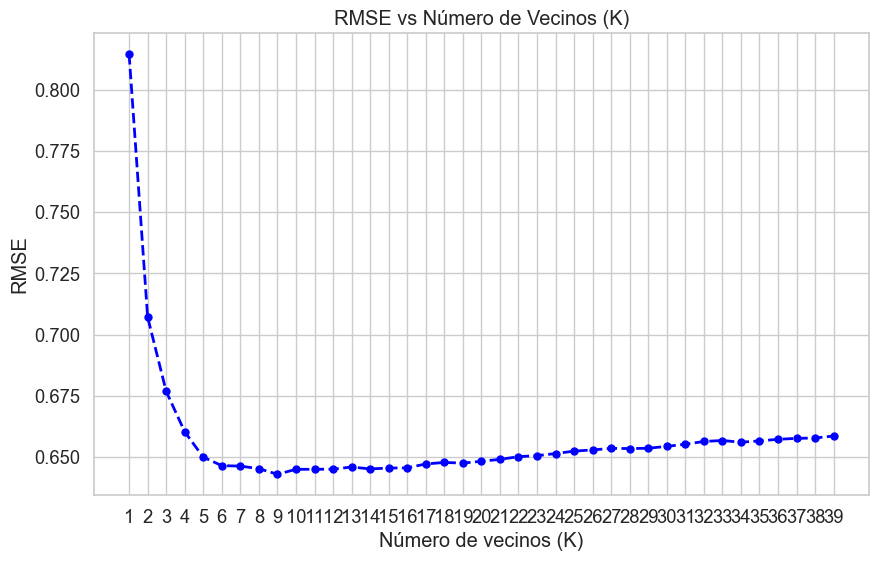

In [84]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

rmse_error = []

# Calcular el RMSE para valores de K entre 1 y 39
for i in range(1, 40):
    knn = KNeighborsRegressor(n_neighbors=i)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    mse = mean_squared_error(y_test, pred_i)
    rmse = np.sqrt(mse)
    rmse_error.append(rmse)

# Graficar
plt.figure(figsize=(10, 6))
plt.plot(range(1, 40), rmse_error, color='blue', marker='o', linestyle='dashed', linewidth=2, markersize=5)
plt.title('RMSE vs Número de Vecinos (K)')
plt.xlabel('Número de vecinos (K)')
plt.ylabel('RMSE')
plt.xticks(range(1, 40))
plt.grid(True)
plt.show()


## Ejercicio 3. Utilizando KNN para detección de valores atípicos con Scikit-Learn

Además de usar KNN para la regresión  y para la clasificación, también podemos usar KNN para detectar qué valores son diferentes de la mayoría (los que no siguen lo que hacen la mayoría de los datos). En otras palabras, podemos usar KNN para detectar valores atípicos.


La idea intuitiva: En clasificación y regresión, KNN predice etiquetas. Aquí el uso es diferente: no predice nada, solo mide distancias. La lógica es simple: un punto normal está rodeado de vecinos cercanos. Un outlier está "solo" en el espacio, lejos de todos sus vecinos.

La detección de valores atípicos utiliza otro método que difiere de lo que habíamos hecho anteriormente para la regresión y la clasificación.

Aquí, veremos qué tan lejos está cada uno de los vecinos de un punto de datos. Usemos los 5 vecinos predeterminados. Para un punto de datos, calcularemos la distancia a cada uno de los K vecinos más cercanos. Para hacer eso, importaremos otro algoritmo KNN de Scikit-learn que no es específico ni para la regresión ni para la clasificación llamado simplemente NearestNeighbors.

Qué es el algoritmo k-Nearest Neighbor ?

Es un método que simplemente busca en las observaciones más cercanas a la que se está tratando de predecir y clasifica el punto de interés basado en la mayoría de datos que le rodean.

In [86]:
from sklearn.neighbors import NearestNeighbors

nbrs = NearestNeighbors(n_neighbors = 5)
nbrs.fit(X_train)
# Distances and indexes of the 5 neighbors 
distances, indexes = nbrs.kneighbors(X_train)

##`NearestNeighbors`** no es un clasificador ni un regresor. Es simplemente un buscador de vecinos. No necesita `y_train` porque no hay nada que predecir, 
## solo mapea el espacio de features.

## nbrs.kneighbors(X_train)`** devuelve dos matrices para cada punto: las distancias a sus 5 vecinos más cercanos y los índices de quiénes son esos vecinos.

Ahora tenemos 5 distancias para cada punto de datos: la distancia entre él y sus 5 vecinos, y un índice que los identifica. Echemos un vistazo a los primeros tres resultados y a la forma de la matriz para visualizar esto mejor.

Para ver la forma de las primeras tres distancias, ejecute:

In [88]:
distances[:3], distances.shape

(array([[0.        , 0.16183013, 0.36006589, 0.39424419, 0.47200917],
        [0.        , 0.23695634, 0.26001269, 0.26500644, 0.26870895],
        [0.        , 0.46539728, 0.68927522, 0.69590921, 0.7053128 ]]),
 (15480, 5))

```
La matriz tiene forma (15480, 5): 15480 puntos en el dataset, cada uno con 5 distancias.
La primera distancia siempre es 0.0 porque el vecino más cercano de un punto es él mismo.
Mirando las tres filas mostradas puedes ver algo importante:

Punto 1: distancias [0, 0.16, 0.36, 0.39, 0.47] → vecinos relativamente cercanos, punto probablemente normal
Punto 2: distancias [0, 0.24, 0.26, 0.27, 0.27] → vecinos muy cercanos y similares entre sí, punto claramente normal y en zona densa
Punto 3: distancias [0, 0.47, 0.69, 0.70, 0.71] → vecinos lejanos, candidato a outlier

Observa que hay 3 filas con 5 distancias cada una. También podemos ver los índices de los vecinos. Esto da como resultado:

En el resultado anterior, podemos ver los índices de cada uno de los 5 vecinos. Ahora, podemos continuar calculando la media de las 5 distancias y trazar un gráfico que cuente cada fila en el eje X y muestre cada distancia media en el eje Y:

Text(0, 0.5, 'Mean Distances')

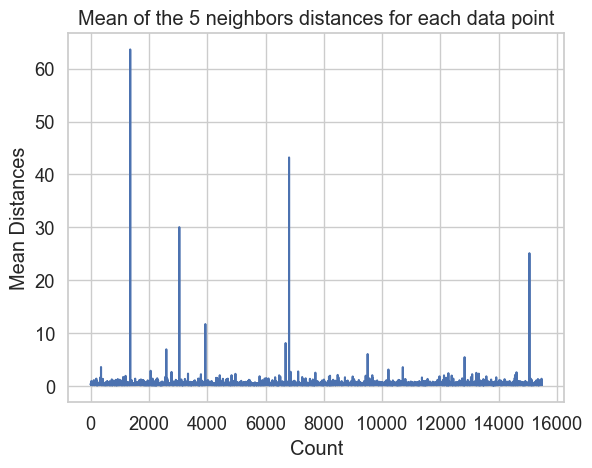

In [90]:
dist_means = distances.mean(axis=1)
plt.plot(dist_means)
plt.title('Mean of the 5 neighbors distances for each data point')
plt.xlabel('Count')
plt.ylabel('Mean Distances')

Observe que hay una parte del gráfico en la que las distancias medias tienen valores uniformes. Ese punto del eje Y en el que las medias no son ni demasiado altas ni demasiado bajas es exactamente el punto que necesitamos identificar para eliminar los valores atípicos. En este caso, es donde la distancia media es 3. Dibujemos el gráfico nuevamente con una línea de puntos horizontal para poder localizarlo:

Interpretación del gráfico. Qué muestra?

El eje X es simplemente el índice de cada punto en el dataset (del 0 al 15,480). El eje Y es la distancia media a sus 5 vecinos más cercanos. Cada línea vertical es un punto de datos.


Los picos: los outliers detectados
Los picos que se disparan son los valores atípicos. Los más notorios son:

- índice 1500: distancia media ≈ 64 → el outlier más extremo de todo el dataset
- índice 3000: distancia media ≈ 30
- índice 4000: distancia media ≈ 12
- índice 6500: distancia media ≈ 43
- índice 15000: distancia media ≈ 25

La intuición geométrica


Imagina que los datos son personas en una ciudad. La mayoría vive en barrios densos, con vecinos a pocos metros. Los outliers son personas que viven en el campo, donde el vecino más cercano está a kilómetros. La distancia media al vecino es la métrica que captura exactamente esa "soledad" en el espacio.

Podemos averiguar los índices de esos puntos utilizando np.where(). Este método generará Verdadero o Falso para cada índice en relación a la regla de 3 sigmas.

```
La Regla de los 3 Sigmas (tres desviaciones estandar)

El origen: la distribución normal
Si los datos siguen una distribución normal, existe una propiedad matemática bien establecida sobre cómo se distribuyen los valores alrededor de la media:

Dentro de ±1σ cae el 68.27% de los datos
Dentro de ±2σ cae el 95.45% de los datos
Dentro de ±3σ cae el 99.73% de los datos

Esto significa que solo el 0.27% de las observaciones queda fuera de 3 sigmas. En un dataset de 15,480 puntos como el tuyo, eso serían apenas ~42 puntos. Todo lo que quede fuera es tan improbable bajo normalidad que merece ser investigado.
La intuición
La pregunta que responde la regla es: ¿qué tan sorprendente es este punto dado lo que espero ver normalmente?
Un punto a 1σ de la media es completamente ordinario. Uno a 2σ es inusual pero posible. Uno a 3σ es tan raro que o bien es un outlier genuino, o algo salió mal en la recolección de datos.

In [92]:
umbral = dist_means.mean() + 3 * dist_means.std()  # regla de 3 sigmas
outliers = np.where(dist_means > umbral)[0]
print(f"Outliers detectados: {len(outliers)}")
print(f"Índices: {outliers}")

Outliers detectados: 17
Índices: [  351  1353  2054  2592  2772  3038  3932  6688  6806  6859  7118  9504
 10217 10711 12832 14614 15057]


Los puntos por encima del umbral son candidatos a inspección manual, errores de captura de datos, o casos genuinamente excepcionales que merecen atención especial.

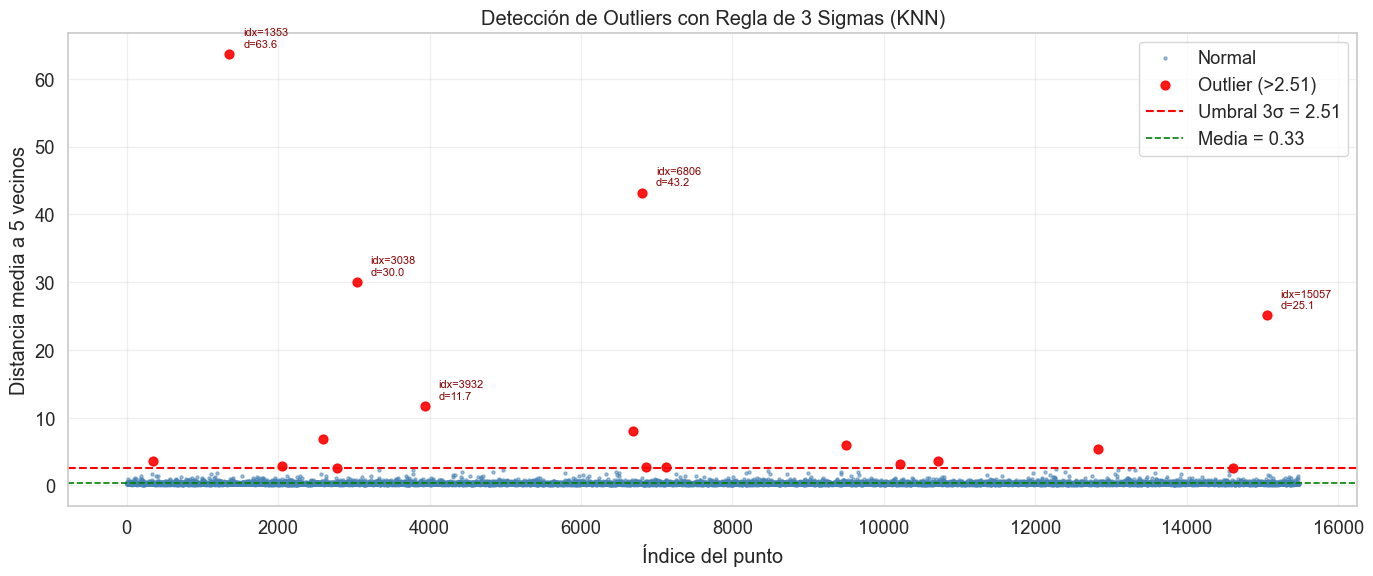

Media de distancias:     0.3318
Desviación estándar:     0.7256
Umbral (media + 3σ):     2.5087
Outliers detectados:     17 (0.11%)

Índices de outliers:
[  351  1353  2054  2592  2772  3038  3932  6688  6806  6859  7118  9504
 10217 10711 12832 14614 15057]


In [94]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Calcular el umbral
media = dist_means.mean()
sigma = dist_means.std()
umbral = media + 3 * sigma

# 2. Identificar outliers y puntos normales
indices = np.arange(len(dist_means))
es_outlier = dist_means > umbral

# 3. Graficar
fig, ax = plt.subplots(figsize=(14, 6))

# Puntos normales en azul
ax.scatter(indices[~es_outlier], dist_means[~es_outlier], 
           color='steelblue', s=5, alpha=0.5, label='Normal')

# Outliers en rojo
ax.scatter(indices[es_outlier], dist_means[es_outlier], 
           color='red', s=40, alpha=0.9, label=f'Outlier (>{umbral:.2f})')

# Línea del umbral
ax.axhline(y=umbral, color='red', linestyle='--', linewidth=1.5, 
           label=f'Umbral 3σ = {umbral:.2f}')

# Línea de la media
ax.axhline(y=media, color='green', linestyle='--', linewidth=1.2,
           label=f'Media = {media:.2f}')

# Etiquetas en los outliers más extremos (top 5)
top_outliers = np.argsort(dist_means)[-5:]
for idx in top_outliers:
    ax.annotate(f'idx={idx}\nd={dist_means[idx]:.1f}', 
                xy=(idx, dist_means[idx]),
                xytext=(10, 5), textcoords='offset points',
                fontsize=8, color='darkred')

ax.set_title('Detección de Outliers con Regla de 3 Sigmas (KNN)')
ax.set_xlabel('Índice del punto')
ax.set_ylabel('Distancia media a 5 vecinos')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Reporte
n_outliers = es_outlier.sum()
print(f"Media de distancias:     {media:.4f}")
print(f"Desviación estándar:     {sigma:.4f}")
print(f"Umbral (media + 3σ):     {umbral:.4f}")
print(f"Outliers detectados:     {n_outliers} ({n_outliers/len(dist_means)*100:.2f}%)")
print(f"\nÍndices de outliers:\n{indices[es_outlier]}")

## Pros y contras de KNN 

##### Ventajas:


- Es fácil de implementar

- Es un algoritmo de aprendizaje lento y, por lo tanto, no requiere entrenamiento en todos los puntos de datos (solo usa los K-vecinos más cercanos para predecir). Esto hace que el algoritmo KNN sea mucho más rápido que otros algoritmos que requieren entrenamiento con todo el conjunto de datos, como máquinas de vectores de soporte, regresión lineal, etc.
  
- Dado que KNN no requiere entrenamiento antes de realizar predicciones, se pueden agregar nuevos datos sin problemas
  
- Solo se requieren dos parámetros para trabajar con KNN, es decir, el valor de K y la función de distancia.

##### Desventajas:

- El algoritmo KNN no funciona bien con datos de alta dimensión porque con una gran cantidad de dimensiones, la distancia entre puntos se vuelve "rara" y las métricas de distancia que usamos no se sostienen.

- Finalmente, el algoritmo KNN no funciona bien con características categóricas ya que es difícil encontrar la distancia entre dimensiones con características categóricas.

- Tiene como contras que utiliza todo el dataset para entrenar “cada punto” y por eso requiere de uso de mucha memoria y recursos de procesamiento (CPU). Por estas razones kNN tiende a funcionar mejor en datasets pequeños y sin una cantidad enorme de features (las columnas).

#### Conclusión

Ahora que ya sabe todo sobre el algoritmo kNN, está listo para comenzar a crear modelos predictivos de alto rendimiento en Python. Se necesitan unos pocos pasos para pasar de un modelo kNN básico a un modelo totalmente optimizado, ¡pero el aumento de rendimiento vale totalmente la pena!

En este tutorial aprendiste a:

- Comprender los fundamentos matemáticos detrás del algoritmo kNN
- Codificar el algoritmo kNN desde cero en NumPy
- Usar la implementación de scikit-learn para ajustar un kNN con una cantidad mínima de código
- Usar GridSearchCV para encontrar los mejores hiperparámetros kNN
- Llevar kNN a su máximo rendimiento usando bagging

Una de las ventajas de las herramientas de ajuste de modelos es que muchas de ellas no solo se pueden aplicar al algoritmo kNN, sino también a muchos otros algoritmos de aprendizaje automático. 

## Ejercicio 4. Utilizando KNN para imputacion de valores faltantes con KNNImputer

KNNImputer de scikit-learn es un método ampliamente utilizado para imputar valores faltantes. Se considera un sustituto frecuente de las técnicas de imputación tradicionales.

La mayoría de los algoritmos estadísticos y de aprendizaje automático funcionan con observaciones completas de un conjunto de datos. Por lo tanto, es esencial abordar la información faltante. Diversos estudios estadísticos abordan el origen de los valores faltantes y las maneras de solucionar este problema. La mejor manera es imputar estas observaciones faltantes con un valor estimado.

En este ultimo apartado, presentamos una guía para imputar valores faltantes en un conjunto de datos utilizando los valores de las observaciones de puntos de datos vecinos. Para ello, utilizamos el popular algoritmo KNNImputer de scikit-learn, "k-Nearest Neighbors".

Los métodos univariados utilizados para la imputación de valores faltantes son métodos simplistas para estimar el valor y podrían no ofrecer siempre una imagen precisa. Por ejemplo, supongamos que tenemos variables relacionadas con la densidad de vehículos en carretera y los niveles de contaminantes en el aire, y que faltan algunas observaciones para el nivel de contaminantes; imputar el nivel de contaminantes mediante la media/mediana podría no ser necesariamente una estrategia adecuada.

## ¿Cómo funciona KNN Imputer?

Funciona KNNImputerencontrando los k vecinos más cercanos (basándose en una métrica de distancia específica) para los puntos de datos con valores faltantes. Posteriormente, imputa los valores faltantes utilizando la media o la mediana (según la estrategia especificada) de los puntos de datos vecinos. La principal ventaja de este enfoque es que preserva las relaciones entre las características, lo que puede mejorar el rendimiento del modelo.

Por ejemplo, considere un conjunto de datos con un valor faltante en una columna que representa la puntuación de matemáticas de un estudiante. En lugar de simplemente completar este valor faltante con la media o mediana general de las puntuaciones de matemáticas, KNNImputerencuentra los k estudiantes más cercanos (basándose en otras características, como las puntuaciones en física, química, etc.) e imputa el valor faltante utilizando la media o mediana de las puntuaciones de matemáticas de estos estudiantes vecinos.

In [102]:
import pandas as pd
import numpy as np

# Define el diccionario
data = {
    'Maths': [80, 90, np.nan, 95],
    'Chemistry': [60, 65, 56, np.nan],
    'Physics': [np.nan, 57, 80, 78],
    'Biology': [78, 83, 67, np.nan]
}

# Crear el DataFrame
df = pd.DataFrame(data)

# Mostrar el DataFrame
df.head()

,Maths,Chemistry,Physics,Biology
0,80.0,60.0,NaN,78.0
1,90.0,65.0,57.0,83.0
2,NaN,56.0,80.0,67.0
3,95.0,NaN,78.0,NaN


In [104]:
# crear un objeto para KNNImputer
imputer = KNNImputer(n_neighbors=2)
df1= imputer.fit_transform(df)
df1 = pd.DataFrame(df1)
df1.head()

,0,1,2,3
0,80.0,60.0,68.5,78.0
1,90.0,65.0,57.0,83.0
2,87.5,56.0,80.0,67.0
3,95.0,58.0,78.0,72.5


nota: n_neighbors: número de puntos de datos a incluir más cercanos al valor faltante. metric: la métrica de distancia que se utilizará para la búsqueda. values - {nan_euclidean. callable} por defecto - nan_euclidean weights: para determinar sobre qué base se deben tratar los valores vecinos values -{uniform , distance, callable} por defecto - uniform.

## Ventajas de usar KNNImputer

Conserva las relaciones: al utilizar los k vecinos más cercanos, este método conserva las relaciones entre las características, lo que puede mejorar el rendimiento del modelo.
Personalizable: la capacidad de personalizar la cantidad de vecinos, la métrica de distancia y el esquema de ponderación lo hace KNNImputeraltamente versátil y adaptable a diferentes tipos de datos.
Maneja diferentes tipos de datos: se puede utilizar con datos continuos y categóricos, lo que lo convierte en una herramienta flexible para una amplia gama de aplicaciones. KNNImputer

## Limitaciones de KNNImputer

- Computacionalmente intensivo: encontrar los k vecinos más cercanos para cada valor faltante puede ser computacionalmente costoso, especialmente para conjuntos de datos grandes con muchos valores faltantes.
- Sensible a valores atípicos: el método puede verse influenciado por valores atípicos en el conjunto de datos, ya que los valores atípicos pueden distorsionar la imputación al sesgar la media de los vecinos.
- Requiere datos suficientes: funciona mejor cuando hay suficientes datos para encontrar vecinos fiables. 